In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [120]:
df = pd.read_csv("../../course_assignments/homework9/solar_system.csv")

In [4]:
df.shape # there are 20 rows and 11 columns

(20, 11)

In [5]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [6]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [7]:
print(list(df.columns))

['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']


In [8]:
print(list(df["Attribute"]))

['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)', 'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)', 'Length of Day (hours)', 'Distance from Sun (10^6 km)', 'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)', 'Orbital Velocity (km/s)', 'Orbital Inclination (deg)', 'Orbital Eccentricity', 'Obliquity to Orbit (deg)', 'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons', 'Ring System?', 'Global Magnetic Field?']


In [182]:
orbT = df.iloc[10, 1:].astype(float)
per = df.iloc[8, 1:].astype(float)
ap = df.iloc[9, 1:].astype(float)

In [122]:
# perihelion: the closest distance between a planet and the sun
# aphelion: the farthest distance between a planet and the sun
# semi-major axis: 1/2 of the major axis (the longer axis of an ellipse)

In [123]:
semi_major_axis = ["Semi-Major Axis (10^6 km)"]
for planet in df.columns[1:]:
    per_planet = per[planet]
    ap_planet = ap[planet]
    addition = (per_planet + ap_planet) / 2
    semi_major_axis.append(addition)

semi_major_axis = pd.DataFrame(semi_major_axis).T
semi_major_axis.columns = ['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']
df = pd.concat([df, semi_major_axis], axis = 0, ignore_index = True)

In [161]:
print(semi_major_axis.T)
print(orbT)

                                   0
Attribute  Semi-Major Axis (10^6 km)
Mercury                         57.9
Venus                          108.2
Earth                          149.6
Moon                          0.3845
Mars                           228.0
Jupiter                        778.5
Saturn                       1432.05
Uranus                       2867.05
Neptune                       4515.0
Pluto                        5906.35
Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: 10, dtype: float64


In [162]:
df.shape # there are now 21 rows and 11 columns

(21, 11)

In [125]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [126]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown
20,Semi-Major Axis (10^6 km),57.9,108.2,149.6,0.3845,228.0,778.5,1432.05,2867.05,4515.0,5906.35


In [127]:
print(list(df.columns))

['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']


In [128]:
print(list(df["Attribute"]))

['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)', 'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)', 'Length of Day (hours)', 'Distance from Sun (10^6 km)', 'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)', 'Orbital Velocity (km/s)', 'Orbital Inclination (deg)', 'Orbital Eccentricity', 'Obliquity to Orbit (deg)', 'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons', 'Ring System?', 'Global Magnetic Field?', 'Semi-Major Axis (10^6 km)']


In [129]:
m_i = df.index[df["Attribute"] == "Mass(10^24 kg)"]
df.iloc[m_i, 1:] = df.iloc[m_i, 1:].astype(float)

In [130]:
a = df.iloc[df.index[df["Attribute"] == "Semi-Major Axis (10^6 km)"], 1:]
T = df.iloc[df.index[df["Attribute"] == "Orbital Period (days)"], 1:]
m = df.iloc[df.index[df["Attribute"] == "Mass (10^24kg)"], 1:]

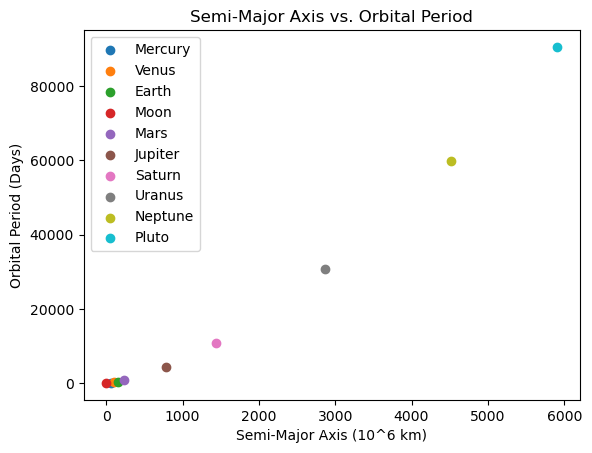

In [132]:
plt.figure()

for planet in df.columns[1:]: 
    plt.scatter(a[planet].iloc[0], T[planet].iloc[0], label = planet)

plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (Days)")
plt.title("Semi-Major Axis vs. Orbital Period")
plt.legend()

plt.show()

In [163]:
def keplers_third_law(a, m): 
    return (m * a ** 1.5)

In [170]:
planets = df.columns[1:]

a = df.loc[df["Attribute"] == "Semi-Major Axis (10^6 km)", planets].iloc[0].astype(float)
T = df.loc[df["Attribute"] == "Orbital Period (days)", planets].iloc[0].astype(float)

popt, pcov = curve_fit(keplers_third_law, a, T)

m = popt[0]
print("Fitted coefficient:", m)

Fitted coefficient: 0.1987998191813986


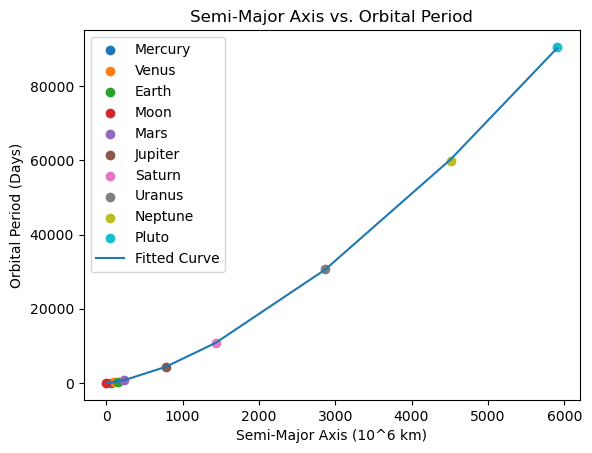

In [180]:
plt.figure()

for planet in df.columns[1:]: 
    plt.scatter(a[planet], T[planet], label = planet)

plt.plot(a, keplers_third_law(a, m), label = "Fitted Curve")

plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (Days)")
plt.title("Semi-Major Axis vs. Orbital Period")
plt.legend()

plt.show()

In [181]:
df.to_csv("kepler.csv", index=False)